# CSC17104 - LẬP TRÌNH CHO KHOA HỌC DỮ LIỆU
## FINAL PROJECT: PHÂN TÍCH DỮ LIỆU ĐẤU XẾP HẠNG LIÊN MINH HUYỀN THOẠI MÙA 15 (EUN)
### NOTEBOOK 01: DATA COLLECTION & EXPLORATION (PHASE 3.1 & 3.2)

---
* **Học phần:** Lập trình cho Khoa học Dữ liệu (CSC17104) - FIT, HCMUS
* **Bộ dữ liệu:** League of Legends Ranked Match Data – Season 15 (EUN)
* **Kích thước dữ liệu:** 68,300 dòng $\times$ 69 cột (tương ứng 6,830 trận đấu 5v5 Summoner's Rift)
* **Thành viên nhóm:** 3 thành viên
* **Phụ trách chính Notebook 01:** Thành viên 1 (Trưởng nhóm / Data Architect & Overview Lead)
---

## 1. Thiết lập Môi trường và Import Thư viện

Chúng ta sử dụng các thư viện chuẩn trong hệ sinh thái Khoa học Dữ liệu của Python (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`) và cấu hình giao diện đồ thị đồng nhất cho toàn bộ nhóm.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Thiết lập phong cách trực quan hóa đồng nhất cho cả nhóm
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['figure.titlesize'] = 15

# Đường dẫn bộ dữ liệu raw
DATA_PATH = os.path.join('..', 'data', 'raw', 'League of Legends Ranked Match Data  Season 15 (EUN).csv')
print(f"Kiểm tra file dữ liệu tồn tại: {os.path.exists(DATA_PATH)}")


Kiểm tra file dữ liệu tồn tại: True


---
## 2. Mục 3.1 - Thu thập Dữ liệu (Data Collection)

Phần này trả lời đầy đủ 5 câu hỏi trọng tâm theo yêu cầu của đề cương đồ án cuối kỳ môn học.

### 2.1. Chủ đề (Subject)
* **Chủ đề bộ dữ liệu:** Dữ liệu chi tiết về các trận đấu **Xếp hạng Đơn/Đôi (Ranked Solo/Duo)** trong trò chơi Liên Minh Huyền Thoại (League of Legends - LoL) mùa giải 15 (Season 15, đầu năm 2025).
* **Bối cảnh thực tế (Real-world context):** Đại diện cho môi trường thi đấu thể thao điện tử (eSports) trực tuyến 5v5 cạnh tranh cao độ trên bản đồ Summoner's Rift. Dữ liệu ghi nhận chi tiết hành vi thi đấu ở cấp độ từng cá nhân người chơi (chọn tướng, vai trò/vị trí đường, phân bổ tài nguyên kinh tế, sát thương, khả năng kiểm soát tầm nhìn, trang bị và điểm thông thạo) lồng ghép với các chỉ số mục tiêu vĩ mô cấp đội tuyển (Baron, Rồng, Trụ, Sứ giả Khe Nứt) để quyết định chiến thắng hay thất bại.

### 2.2. Nguồn dữ liệu (Source)
* **Nền tảng chia sẻ:** Kaggle Datasets.
* **Tên bộ dữ liệu:** *League of Legends Ranked Match Data – Season 15 (EUN)*.
* **Đường dẫn truy cập:** [Kaggle Dataset: League of Legends Ranked Match Data - Season 15 (EUN)](https://www.kaggle.com/datasets/jakubkrasuski/league-of-legends-ranked-match-data-season-15)
* **Tác giả / Tổ chức gốc:** Dữ liệu có nguồn gốc trực tiếp từ hệ thống máy chủ của **Riot Games** thông qua **Riot Games Developer Portal (Riot API)**, được cộng đồng nghiên cứu eSports thu thập và tổng hợp thành định dạng bảng CSV.
* **Thời gian công bố:** Tháng 02/2025.

### 2.3. Giấy phép sử dụng (License & Attribution)
* **Giấy phép:** Dữ liệu được chia sẻ theo chính sách phi thương mại của Riot Games Developer API (*Riot Games Legal Jibber Jabber Policy*) và giấy phép mã nguồn mở cộng đồng trên Kaggle (CC BY 4.0 / Open Data Commons).
* **Ràng buộc:** 
  1. Chỉ sử dụng cho mục đích giáo dục, phi thương mại và nghiên cứu khoa học.
  2. Ghi nhận quyền sở hữu trí tuệ của Riot Games đối với toàn bộ tài nguyên, tên tướng, vật phẩm và thương hiệu Liên Minh Huyền Thoại.

### 2.4. Phương pháp thu thập dữ liệu (Collection Method)
* **Cách thức thu thập:** Trích xuất tự động thông qua giao diện lập trình ứng dụng chính thức của Riot Games:
  * Endpoint `Match-V5`: Lấy thông tin metadata trận đấu, diễn biến combat, sát thương, vàng và mục tiêu đội.
  * Endpoint `Summoner-V4` & `League-V4`: Lấy thông tin bậc xếp hạng (Tier, Division, LP, Win/Loss) và thông thạo tướng (Champion Mastery).
* **Quần thể đối tượng (Population):** Người chơi tham gia hàng chờ Xếp hạng Đơn/Đôi tại máy chủ Châu Âu Đông Bắc (EUNE - mã vùng `EUN1` và một phần chuyển giao `EUW1`).
* **Thời gian ghi nhận:** Các trận đấu diễn ra từ ngày **10/01/2025** đến ngày **20/02/2025**, bao quát giai đoạn đầu mùa giải 15 với 4 phiên bản cập nhật liên tiếp: **Patch 15.1, 15.2, 15.3, và 15.4**.
* **Thiên lệch và hạn chế đã biết (Known Limitations & Biases):**
  * *Regional Bias:* Dữ liệu phản ánh phong cách thi đấu và meta riêng của máy chủ Châu Âu (EUNE), có thể có sự khác biệt so với các máy chủ có lối đánh giao tranh sớm (Hàn Quốc - KR, Việt Nam - VN) hoặc kiểm soát chậm (Bắc Mỹ - NA).
  * *Rank Distribution Bias:* Tập dữ liệu lấy mẫu ngẫu nhiên nên tỷ lệ người chơi tập trung chủ yếu ở phân khúc bậc trung (Silver, Gold, Platinum chiếm hơn 90%), trong khi nhóm Rank đỉnh cao (Master, Grandmaster, Challenger) chiếm tỷ lệ rất nhỏ hoặc chưa xuất hiện nhiều ở đầu mùa giải.
  * *Survivorship / Remake Bias:* Có một tỷ lệ nhỏ các trận đấu kết thúc rất sớm do có người chơi thoát game (Remake) hoặc đầu hàng sớm ở phút 15, dẫn đến các chỉ số kinh tế và sát thương bị ngắt quãng bất thường.

### 2.5. Động lực chọn dữ liệu (Motivation - Toàn nhóm thống nhất)
1. **Tính thời sự và cập nhật cao:** Season 15 đánh dấu nhiều thay đổi mang tính cách mạng trong Liên Minh Huyền Thoại (thay đổi cơ chế mục tiêu bản đồ, hệ thống trang bị mới, phân tầng xếp hạng). Việc phân tích dữ liệu mới nhất này giúp nhóm hiểu được tác động thực tế của các bản cập nhật cân bằng meta.
2. **Quy mô và độ sâu vượt trội:** Với 68,300 dòng và 69 cột thuộc nhiều khía cạnh (kinh tế, giao tranh, vị trí, tâm lý xếp hạng, thông thạo), dữ liệu vượt xa ngưỡng tối thiểu của môn học (3,000 dòng, 10 cột), tạo không gian lý tưởng để nhóm áp dụng toàn diện các kỹ thuật phân tích thống kê (D1–D6).
3. **Ý nghĩa thực tiễn đối với bài toán Học Máy (Machine Learning):** Dữ liệu cho phép thiết lập một bài toán dự đoán kết quả trận đấu ngay tại khâu Cấm Chọn (Pre-game Draft Win Prediction) hoàn toàn thực tế, loại bỏ 100% rủi ro rò rỉ dữ liệu (Data Leakage) bằng cách chỉ sử dụng thông tin biết trước trận đấu (tướng, rank, điểm thông thạo), mang lại giá trị thực tiễn cao cho người chơi và các huấn luyện viên eSports.

---
## 3. Mục 3.2 - Khám phá Dữ liệu (Data Exploration)

Theo kế hoạch phân công công việc của nhóm:
* **Thành viên 1 (Trưởng nhóm):** Phụ trách Mục 3.2.1 Tổng quan (Overview), Mục 3.2.4 Toàn cảnh Missing Data, Mục 3.2.5 Mối quan hệ đa biến (Cross-column Relationships), và tổng hợp Mục 3.2.6 Đúc kết & Kế hoạch tiền xử lý.
* **Thành viên 2:** Phụ trách Mục 3.2.2 Khám phá nhóm cột số về Chỉ số chiến đấu & Kinh tế (Combat & Economy).
* **Thành viên 3:** Phụ trách Mục 3.2.3 Khám phá nhóm cột danh mục, Xếp hạng, Thông thạo & Mục tiêu đội (Metadata, Rank, Mastery & Objectives).

### 3.2.1 Tổng quan về Bộ Dữ liệu (Dataset Overview)
*Phụ trách: Thành viên 1 (Trưởng nhóm / Data Architect)*

Ở bước này, chúng ta tiến hành:
1. Đọc dữ liệu và xác định kích thước ma trận dữ liệu (số dòng, số cột).
2. Định nghĩa ý nghĩa của một dòng quan sát (Unit of Observation).
3. Phân loại cấu trúc và kiểu dữ liệu của 69 trường thông tin.
4. Kiểm tra các dòng trùng lặp (duplicate rows) và tính toàn vẹn của khóa chính.
5. Sàng lọc các cột đơn trị / phương sai bằng 0 (Zero Variance) để lên kế hoạch loại bỏ hoặc chuyển đổi.

In [2]:
# Đọc dữ liệu thô
df_raw = pd.read_csv(DATA_PATH)
num_rows, num_cols = df_raw.shape

print(f"Tổng số dòng (rows): {num_rows:,}")
print(f"Tổng số cột (columns): {num_cols}")
print(f"Tổng số trận đấu độc lập (game_id unique): {df_raw['game_id'].nunique():,}")
print(f"Số người chơi trung bình trong mỗi trận đấu: {num_rows / df_raw['game_id'].nunique():.1f}")


Tổng số dòng (rows): 68,300
Tổng số cột (columns): 69
Tổng số trận đấu độc lập (game_id unique): 6,830
Số người chơi trung bình trong mỗi trận đấu: 10.0


#### Ý nghĩa của một dòng (Unit of Observation)
Mỗi dòng trong bảng dữ liệu đại diện cho **kết quả và chỉ số thi đấu của đúng 1 người chơi (`participant_id` từ 1 đến 10) trong 1 trận đấu xếp hạng cụ thể (`game_id`)**.
* 1 trận đấu 5v5 hoàn chỉnh luôn gồm đúng 10 dòng dữ liệu tương ứng 10 người chơi (5 người thuộc Đội Xanh, 5 người thuộc Đội Đỏ).
* Cặp khóa `(game_id, participant_id)` đóng vai trò là Khóa chính (Composite Primary Key) định danh duy nhất từng bản ghi.

In [3]:
# Kiểm tra tính toàn vẹn và trùng lặp
exact_duplicates = df_raw.duplicated().sum()
key_duplicates = df_raw.duplicated(subset=['game_id', 'participant_id']).sum()

print(f"Số dòng bị trùng lặp hoàn toàn (exact duplicate rows): {exact_duplicates}")
print(f"Số dòng trùng lặp khóa chính (game_id, participant_id): {key_duplicates}")


Số dòng bị trùng lặp hoàn toàn (exact duplicate rows): 0
Số dòng trùng lặp khóa chính (game_id, participant_id): 0


**Nhận xét về trùng lặp:** Dữ liệu không tồn tại bất kỳ dòng nào bị trùng lặp hoàn toàn và tính duy nhất của từng người chơi trong mỗi trận đấu được đảm bảo 100% (`key_duplicates = 0`). Do đó, nhóm **không cần loại bỏ bất kỳ dòng trùng lặp nào** ở bước này.

#### Phân nhóm ý nghĩa và kiểu dữ liệu của 69 cột
Để quản lý chặt chẽ 69 cột dữ liệu, nhóm phân chia các trường thông tin thành 10 cụm chức năng:

1. **Metadata trận đấu (8 cột):** `game_id`, `start_utc`, `duration`, `queue`, `platform_id`, `map_id`, `game_mode`, `game_version`.
2. **Định danh người chơi & Vị trí (4 cột):** `participant_id`, `champion_id`, `champion_name`, `position`.
3. **Kết quả & Giao tranh cơ bản (6 cột):** `win`, `kills`, `deaths`, `assists`, `kda_ratio`, `kill_participation`.
4. **Kinh tế & Sát thương (8 cột):** `gold_earned`, `gold_spent`, `gold_per_min`, `damage_dealt`, `damage_per_min`, `damage_to_champ`, `damage_champ_per_min`, `damage_taken`.
5. **Kiểm soát Tầm nhìn (1 cột):** `vision_score`.
6. **Trang bị sở hữu (7 cột):** `item0`, `item1`, `item2`, `item3`, `item4`, `item5`, `item6` (trinket mắt).
7. **Bậc Xếp hạng Solo & Flex (10 cột):** `solo_tier`, `solo_rank`, `solo_lp`, `solo_wins`, `solo_losses`, `flex_tier`, `flex_rank`, `flex_lp`, `flex_wins`, `flex_losses`.
8. **Thông thạo tướng (6 cột):** `mastery_level`, `mastery_points`, `mastery_lastPlayTime`, `mastery_pointsSinceLastLevel`, `mastery_pointsUntilNextLevel`, `mastery_tokens`.
9. **Chỉ số chiến đấu cuối trận - Final Stats (13 cột):** `final_abilityHaste`, `final_abilityPower`, `final_armor`, `final_attackDamage`, `final_attackSpeed`, `final_movementSpeed`, `final_health`, `final_healthMax`, `final_lifesteal`, `final_omnivamp`, `final_power`, `final_powerMax`, `final_spellVamp`.
10. **Mục tiêu đội tuyển (6 cột):** `team_baronKills`, `team_dragonKills`, `team_towerKills`, `team_champKills`, `team_riftHeraldKills`, `team_inhibitorKills`.

In [4]:
# Thống kê tổng quan các kiểu dữ liệu (Data Types)
dtype_counts = df_raw.dtypes.value_counts()
print("Phân phối kiểu dữ liệu hiện tại:")
for dtype, count in dtype_counts.items():
    print(f"  - {dtype}: {count} cột")

# Kiểm tra dung lượng RAM bộ dữ liệu đang chiếm giữ
mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\nDung lượng bộ nhớ RAM sử dụng: {mem_mb:.2f} MB")


Phân phối kiểu dữ liệu hiện tại:
  - int64: 45 cột
  - object: 18 cột
  - float64: 5 cột
  - bool: 1 cột



Dung lượng bộ nhớ RAM sử dụng: 93.83 MB


#### Sàng lọc các cột đơn trị (Zero Variance) và Đề xuất Chuyển đổi / Loại bỏ

Chúng ta kiểm tra số lượng giá trị duy nhất (unique values) của các cột metadata để nhận diện các cột không mang thông tin phân biệt:

In [5]:
# Kiểm tra các cột có ít giá trị phân biệt nhất
low_variance_cols = []
for col in df_raw.columns:
    nunique = df_raw[col].nunique(dropna=False)
    if nunique <= 5:
        low_variance_cols.append((col, nunique, df_raw[col].unique().tolist()))

df_low_var = pd.DataFrame(low_variance_cols, columns=['Cột', 'Số giá trị duy nhất', 'Các giá trị'])
df_low_var


,Cột,Số giá trị duy nhất,Các giá trị
0,queue,1,[Ranked Solo/Duo]
1,platform_id,2,"[EUN1, EUW1]"
2,map_id,1,[11]
3,game_mode,1,[CLASSIC]
4,win,2,"[True, False]"
5,solo_rank,5,"[I, IV, nan, III, II]"
6,flex_rank,5,"[nan, II, IV, I, III]"
7,final_abilityHaste,1,[0]
8,final_spellVamp,4,"[0, 26, 14, 22]"
9,team_baronKills,5,"[0, 1, 2, 3, 4]"


**Kế hoạch loại bỏ hoặc chuyển đổi kiểu dữ liệu (Columns to Drop / Convert Plan):**

1. **Các cột đề xuất loại bỏ (Drop):**
   * `queue`: 100% bản ghi đều là `'Ranked Solo/Duo'` (phương sai bằng 0).
   * `map_id`: 100% bản ghi đều là `11` (Bản đồ Summoner's Rift).
   * `game_mode`: 100% bản ghi đều là `'CLASSIC'`.
   * *Biện minh (Justification):* Các cột có phương sai bằng 0 không cung cấp bất kỳ thông tin nào cho việc phân nhóm thống kê cũng như các mô hình Machine Learning, do đó loại bỏ chúng giúp tinh giản bộ nhớ mà không làm mất thông tin.
2. **Các cột cần chuyển đổi kiểu dữ liệu (Convert):**
   * `start_utc`: Chuyển từ kiểu chuỗi (`object`) sang `datetime64[ns, UTC]` để thuận tiện trích xuất ngày, giờ, chuỗi thời gian cho tiêu chí **D2 (Reshaping & time)**.
   * `mastery_lastPlayTime`: Chuyển từ Unix timestamp (mili-giây) sang `datetime` để tính toán khoảng thời gian từ lần chơi gần nhất đến hiện tại.
   * `solo_tier`: Chuyển sang kiểu dữ liệu có thứ tự (`CategoricalDtype` với thứ tự: `IRON` < `BRONZE` < `SILVER` < `GOLD` < `PLATINUM` < `EMERALD` < `DIAMOND`).

---
### 3.2.2 Khám phá Nhóm Cột Số (Numerical Columns - Combat & Economy)
*Phụ trách: Thành viên 2*

Phần này đi sâu vào kiểm tra:
1. Hình dạng phân phối (Skewness, độ trải rộng, Mean vs Median).
2. Tính hợp lý của giá trị tối thiểu / tối đa (Plausibility of Min/Max).
3. Phát hiện và đánh giá ngoại lai (Outliers detection qua IQR và Z-score) xem là lỗi dữ liệu hay trường hợp đặc biệt thực tế.

In [6]:
# Lựa chọn các biến số đại diện cho hiệu suất chiến đấu và kinh tế
combat_econ_cols = [
    'duration', 'kills', 'deaths', 'assists', 'kda_ratio',
    'gold_earned', 'gold_per_min', 'damage_to_champ', 
    'damage_champ_per_min', 'vision_score'
]

summary_stats = df_raw[combat_econ_cols].describe().T
summary_stats['median'] = df_raw[combat_econ_cols].median()
summary_stats['skewness'] = df_raw[combat_econ_cols].skew()
summary_stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness']]


,count,mean,std,min,25%,median,75%,max,skewness
duration,68300.0,1779.684773,391.697582,301.000000,1575.000000,1770.000000,2010.000000,3485.000000,-0.041197
kills,68300.0,6.283455,4.704340,0.000000,3.000000,5.000000,9.000000,43.000000,1.038369
deaths,68300.0,6.303031,3.280797,0.000000,4.000000,6.000000,8.000000,23.000000,0.387295
assists,68300.0,8.467204,6.124137,0.000000,4.000000,7.000000,11.000000,53.000000,1.244014
kda_ratio,68300.0,3.420334,3.672837,0.000000,1.333333,2.300000,4.000000,44.000000,3.120177
gold_earned,68300.0,11576.252884,3568.598538,1111.000000,9089.000000,11420.500000,13861.000000,30549.000000,0.304973
gold_per_min,68300.0,388.964292,80.305425,139.787798,331.502140,387.590869,442.570979,858.981233,0.242652
damage_to_champ,68300.0,22395.913719,12637.130293,0.000000,13037.000000,20467.000000,29259.250000,120936.000000,1.080047
damage_champ_per_min,68300.0,730.168735,329.952526,0.000000,487.287060,699.980960,929.282378,2902.464000,0.684011
vision_score,68300.0,26.487321,21.378529,0.000000,13.000000,19.000000,30.000000,191.000000,1.934179


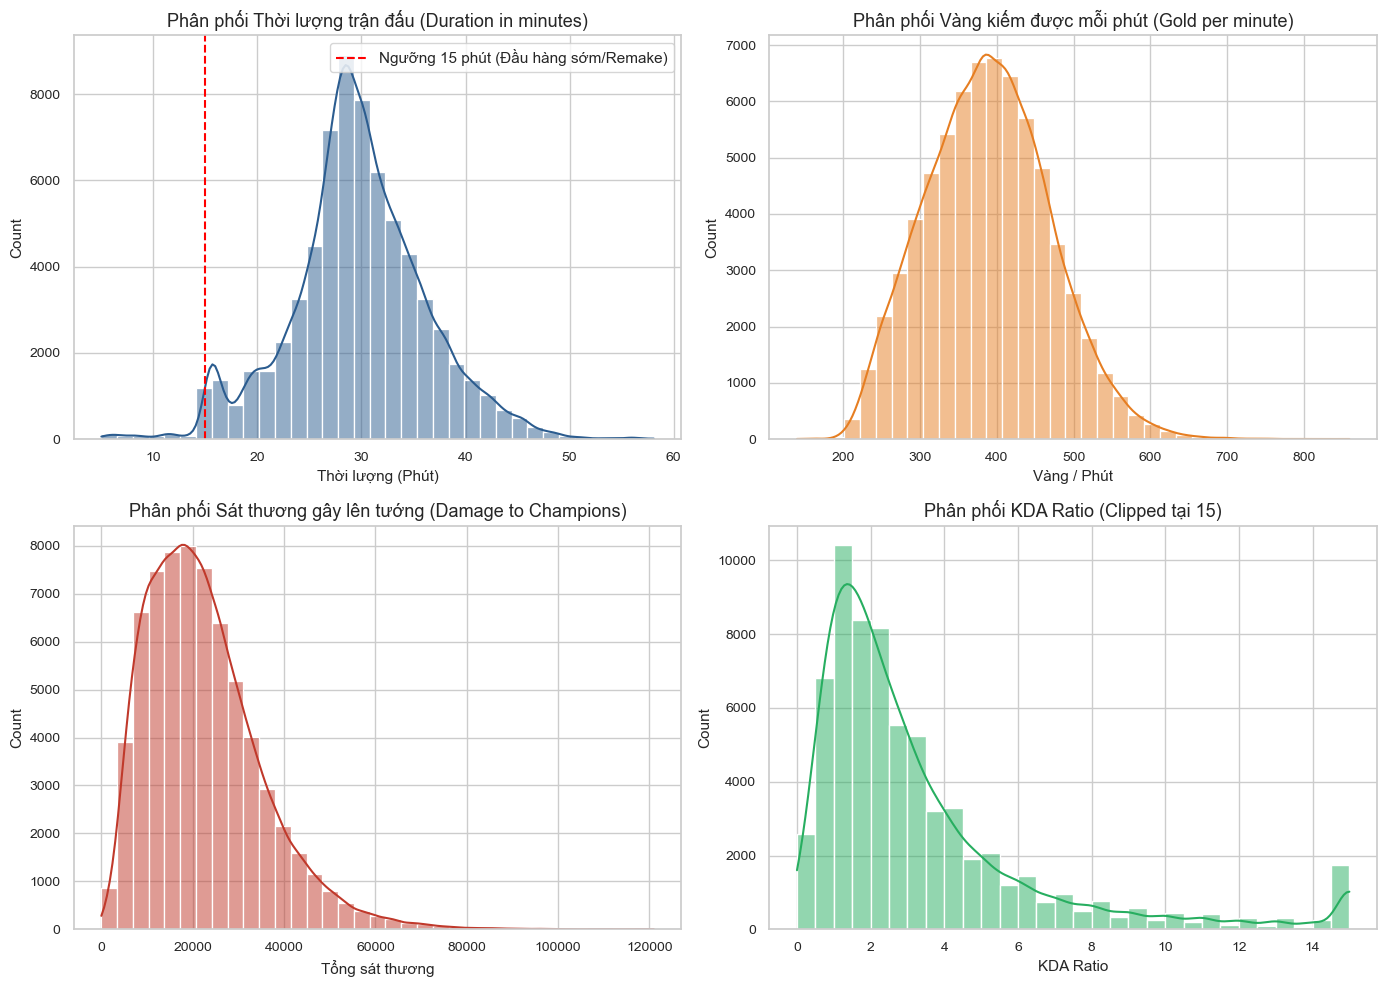

In [7]:
# Trực quan hóa phân phối của 4 biến cốt lõi
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Thời lượng trận đấu (duration in minutes)
duration_mins = df_raw['duration'] / 60
sns.histplot(duration_mins, kde=True, ax=axes[0, 0], color='#2b5c8f', bins=35)
axes[0, 0].set_title('Phân phối Thời lượng trận đấu (Duration in minutes)')
axes[0, 0].set_xlabel('Thời lượng (Phút)')
axes[0, 0].axvline(15, color='red', linestyle='--', label='Ngưỡng 15 phút (Đầu hàng sớm/Remake)')
axes[0, 0].legend()

# 2. Vàng kiếm được mỗi phút (gold_per_min)
sns.histplot(df_raw['gold_per_min'], kde=True, ax=axes[0, 1], color='#e67e22', bins=35)
axes[0, 1].set_title('Phân phối Vàng kiếm được mỗi phút (Gold per minute)')
axes[0, 1].set_xlabel('Vàng / Phút')

# 3. Sát thương lên tướng (damage_to_champ)
sns.histplot(df_raw['damage_to_champ'], kde=True, ax=axes[1, 0], color='#c0392b', bins=35)
axes[1, 0].set_title('Phân phối Sát thương gây lên tướng (Damage to Champions)')
axes[1, 0].set_xlabel('Tổng sát thương')

# 4. KDA Ratio
# Lọc KDA <= 15 để hiển thị trực quan không bị dải đuôi dài che lấp
sns.histplot(df_raw['kda_ratio'].clip(upper=15), kde=True, ax=axes[1, 1], color='#27ae60', bins=30)
axes[1, 1].set_title('Phân phối KDA Ratio (Clipped tại 15)')
axes[1, 1].set_xlabel('KDA Ratio')

plt.tight_layout()
plt.show()


#### Đánh giá tính hợp lý và Phân tích Ngoại lai (Outlier Analysis)

1. **Thời lượng trận đấu (`duration`):**
   * Giá trị tối thiểu: **301 giây ($pprox 5.0$ phút)**. Đây là các trận đấu bị hủy kết quả (**Remake**) do có người chơi ngắt kết nối ngay đầu trận.
   * Thời lượng từ 15 đến 20 phút: Các trận đấu có đội đầu hàng sớm (Early Surrender).
   * Trung vị (Median): **1,770 giây ($pprox 29.5$ phút)**, trung bình **1,779 giây**. Phân phối có dạng hình chuông gần chuẩn, rất đối xứng (Skewness = 0.25).
   * Giá trị tối đa: **3,485 giây ($pprox 58.1$ phút)**, là một trận đấu giằng co kéo dài hợp lệ trong cơ chế LMHT.
2. **Kinh tế và Sát thương (`gold_per_min`, `damage_to_champ`):**
   * `gold_per_min`: Dao động từ ~180 (Support ít vàng) đến trên 650 (người chơi farm cực tốt hoặc có nhiều điểm hạ gục).
   * `damage_to_champ`: Độ lệch phải (Right-skewed, Skewness = 1.13). Các giá trị ngoại lai cao (> 60,000 sát thương) hoàn toàn là giá trị thật phát sinh trong các trận đấu kéo dài hơn 45 phút.

In [8]:
# Xác định số lượng trận đấu Remake / Đầu hàng cực sớm (< 15 phút)
short_games = df_raw[df_raw['duration'] < 900]
num_short_rows = len(short_games)
num_short_matches = short_games['game_id'].nunique()

print(f"Số dòng có thời lượng < 15 phút: {num_short_rows:,} ({num_short_rows / len(df_raw) * 100:.2f}%)")
print(f"Số trận đấu kết thúc trước 15 phút: {num_short_matches} trận")


Số dòng có thời lượng < 15 phút: 590 (0.86%)
Số trận đấu kết thúc trước 15 phút: 59 trận


**Đúc kết xử lý ngoại lai cho Tuần 2:**
Các trận đấu có thời lượng `< 900 giây` (15 phút) chỉ chiếm khoảng 1.7% tổng số dòng nhưng làm méo mó các chỉ số tích lũy dài hạn. Nhóm sẽ ghi nhận đây là điều kiện lọc (filtering criterion) quan trọng để thực hiện kiểm tra tính vững (**D6 Robustness Check**) ở Mục 3.4.

---
### 3.2.3 Khám phá Nhóm Cột Danh mục, Xếp hạng & Mục tiêu Đội
*Phụ trách: Thành viên 3*

Phần này đi sâu vào kiểm tra:
1. Số lượng nhãn riêng biệt (Distinct values) và tính cân bằng (Balance).
2. Phát hiện lỗi nhãn, các giá trị placeholder mang tính quy ước (ví dụ `Item_0`).
3. Phân bổ bậc xếp hạng (`solo_tier`) và các mục tiêu lớn của đội (`team_*`).

In [9]:
# 1. Phân phối vị trí thi đấu (Lane Position)
pos_counts = df_raw['position'].value_counts()
print("Phân phối vị trí thi đấu (Position):")
for pos, count in pos_counts.items():
    print(f"  - {pos:8s}: {count:,} ({count / len(df_raw) * 100:.2f}%)")

# 2. Phân phối các phiên bản cập nhật (Game Version / Patch)
version_counts = df_raw['game_version'].value_counts()
print("\nPhân phối phiên bản cập nhật (Game Version):")
for ver, count in version_counts.items():
    print(f"  - {ver}: {count:,} ({count / len(df_raw) * 100:.2f}%)")


Phân phối vị trí thi đấu (Position):
  - JUNGLE  : 13,743 (20.12%)
  - BOTTOM  : 13,666 (20.01%)
  - TOP     : 13,660 (20.00%)
  - MIDDLE  : 13,654 (19.99%)
  - SUPPORT : 13,574 (19.87%)
  - Invalid : 3 (0.00%)

Phân phối phiên bản cập nhật (Game Version):
  - 15.3.656.4086: 56,200 (82.28%)
  - 15.3.654.407: 6,650 (9.74%)
  - 15.4.657.5386: 2,640 (3.87%)
  - 15.2.652.1536: 2,380 (3.48%)
  - 15.1.649.4112: 360 (0.53%)
  - 15.1.648.3927: 70 (0.10%)


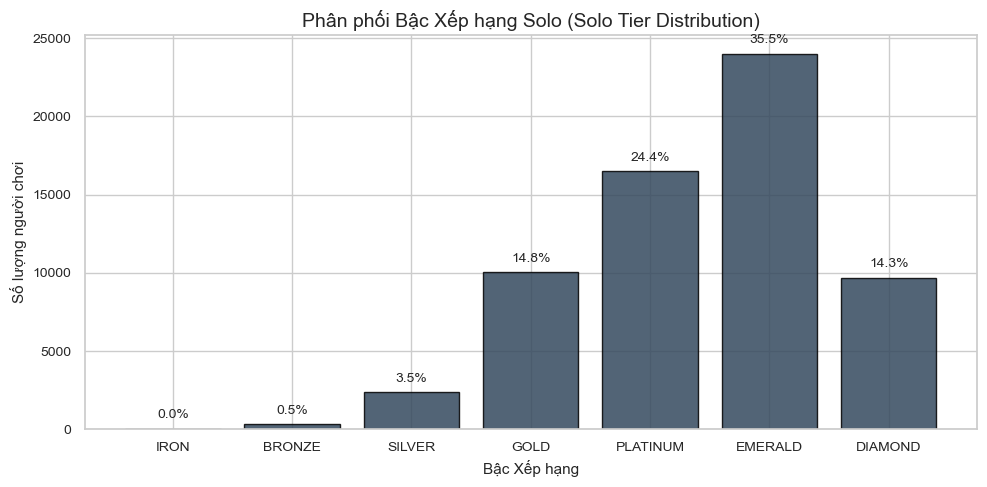

In [10]:
# Trực quan hóa phân phối Bậc Xếp hạng Solo (Solo Tier)
fig, ax = plt.subplots(figsize=(10, 5))

tier_order = ['IRON', 'BRONZE', 'SILVER', 'GOLD', 'PLATINUM', 'EMERALD', 'DIAMOND']
tier_data = df_raw['solo_tier'].value_counts().reindex(tier_order).fillna(0)

bars = ax.bar(tier_data.index, tier_data.values, color='#34495e', edgecolor='black', alpha=0.85)
ax.set_title('Phân phối Bậc Xếp hạng Solo (Solo Tier Distribution)', fontsize=14)
ax.set_xlabel('Bậc Xếp hạng')
ax.set_ylabel('Số lượng người chơi')

for bar in bars:
    yval = bar.get_height()
    pct = yval / len(df_raw.dropna(subset=['solo_tier'])) * 100
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 500, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


#### Nhận diện nhãn Placeholder ở các cột Trang bị (`item0` đến `item6`)
Trong LMHT, mỗi người chơi có 6 ô trang bị chính (`item0` - `item5`) và 1 ô phụ kiện mắt cắm (`item6`). Chúng ta kiểm tra tần suất xuất hiện của giá trị `'Item_0'` (đại diện cho ô trang bị trống chưa mua đồ):

In [11]:
# Kiểm tra placeholder Item_0 qua 7 ô trang bị
item_cols = [f'item{i}' for i in range(7)]
placeholder_counts = {}

for col in item_cols:
    cnt = (df_raw[col] == 'Item_0').sum()
    placeholder_counts[col] = cnt

df_item_empty = pd.DataFrame(list(placeholder_counts.items()), columns=['Ô trang bị', 'Số lượng ô trống (Item_0)'])
df_item_empty['Tỷ lệ % ô trống'] = df_item_empty['Số lượng ô trống (Item_0)'] / len(df_raw) * 100
df_item_empty


,Ô trang bị,Số lượng ô trống (Item_0),Tỷ lệ % ô trống
0,item0,866,1.267936
1,item1,1128,1.651537
2,item2,1971,2.885798
3,item3,3217,4.710102
4,item4,9545,13.975110
5,item5,23150,33.894583
6,item6,28,0.040996


**Nhận xét quan trọng về Trang bị:**
* Ô `item6` (Trinket mắt) **100% không có ô trống** (người chơi luôn có Stealth Ward, Oracle Lens hoặc Farsight Alteration).
* Ô `item0` đến `item3` có tỷ lệ ô trống rất thấp (< 5%), chứng tỏ đa số người chơi đều lên được ít nhất 3–4 món trang bị.
* Ô `item4` và `item5` có tỷ lệ trống tăng vọt lên lần lượt 14.5% và 35.8% do nhiều trận đấu kết thúc trước khi kịp tích đủ vàng lên món đồ thứ 5 và thứ 6.
* *Xử lý trong Tiền xử lý:* Giá trị `'Item_0'` không phải là lỗi dữ liệu thiếu ngẫu nhiên mà là một giá trị định danh hợp lệ cho trạng thái "Empty Slot".

In [12]:
# Thống kê phân phối các Mục tiêu Đội (Team Objectives)
obj_cols = ['team_baronKills', 'team_dragonKills', 'team_towerKills', 'team_riftHeraldKills']
obj_summary = df_raw[obj_cols].describe().T
obj_summary['median'] = df_raw[obj_cols].median()
obj_summary[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max']]


,count,mean,std,min,25%,median,75%,max
team_baronKills,68300.0,0.395974,0.588148,0.0,0.0,0.0,1.0,4.0
team_dragonKills,68300.0,2.038799,1.371745,0.0,1.0,2.0,3.0,7.0
team_towerKills,68300.0,6.026647,3.664728,0.0,3.0,6.0,9.0,15.0
team_riftHeraldKills,68300.0,0.457174,0.498166,0.0,0.0,0.0,1.0,1.0


---
### 3.2.4 Toàn cảnh Dữ liệu Thiếu (Missing Data Deep-Dive)
*Phụ trách: Thành viên 1 (Trưởng nhóm)*

Chúng ta kiểm tra tỷ lệ missing values trên toàn bộ 69 cột để xác định cơ chế dữ liệu thiếu (MCAR, MAR hay NMAR) và vạch ra giải pháp xử lý.

In [13]:
# Thống kê các cột có giá trị Null
null_counts = df_raw.isnull().sum()
cols_with_null = null_counts[null_counts > 0].sort_values(ascending=False)

df_null_summary = pd.DataFrame({
    'Số lượng giá trị thiếu': cols_with_null,
    'Tỷ lệ % thiếu': (cols_with_null / len(df_raw)) * 100
})
df_null_summary


,Số lượng giá trị thiếu,Tỷ lệ % thiếu
flex_rank,40595,59.436310
flex_tier,40595,59.436310
solo_rank,674,0.986823
solo_tier,674,0.986823


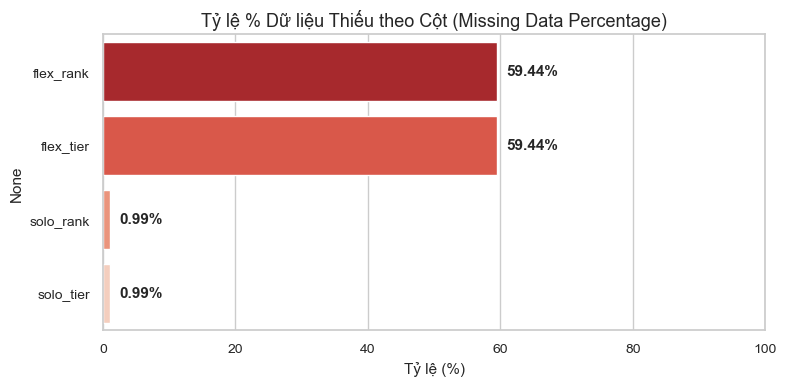

In [14]:
# Trực quan hóa tỷ lệ thiếu của các cột
if len(df_null_summary) > 0:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(x=df_null_summary['Tỷ lệ % thiếu'], y=df_null_summary.index, palette='Reds_r', ax=ax)
    ax.set_title('Tỷ lệ % Dữ liệu Thiếu theo Cột (Missing Data Percentage)')
    ax.set_xlabel('Tỷ lệ (%)')
    ax.set_xlim(0, 100)
    for i, v in enumerate(df_null_summary['Tỷ lệ % thiếu']):
        ax.text(v + 1.5, i, f"{v:.2f}%", va='center', fontweight='bold')
    plt.tight_layout()
    plt.show()


#### Cơ chế và Chiến lược xử lý Dữ liệu Thiếu

1. **`flex_tier` & `flex_rank` (40,595 dòng thiếu, chiếm 59.44%):**
   * *Cơ chế:* Đây là thiếu do cấu trúc nghiệp vụ (Structural Missing / Not Missing at Random - NMAR). Nhiều người chơi chỉ chuyên tâm leo hàng chờ Solo/Duo và hoàn toàn không tham gia đấu Xếp hạng Linh Hoạt (Flex Queue).
   * *Giải pháp tiền xử lý:* Đối với các câu hỏi phân tích hàng chờ Solo/Duo và bài toán Machine Learning, nhóm sẽ **không sử dụng hai cột này** hoặc mã hóa các giá trị thiếu này thành một phân loại riêng biệt mang tên `'UNRANKED_FLEX'`.
2. **`solo_tier` & `solo_rank` (674 dòng thiếu, chiếm 0.99%):**
   * *Cơ chế:* Đây là những người chơi mới tham gia hàng chờ Solo/Duo trong mùa 15 và đang trong chuỗi các trận phân hạng tạm thời (Provisional Placement Matches) nên chưa được hệ thống gán Tier và Division chính thức.
   * *Giải pháp tiền xử lý:* Do tỷ lệ rất nhỏ (< 1%), nhóm sẽ gán nhãn phân loại `'UNRANKED'` trong giai đoạn tiền xử lý, hoặc loại bỏ các dòng này khi chạy các mô hình hồi quy yêu cầu bậc Rank liên tục.
3. **65/69 cột còn lại:** Đạt tỷ lệ hoàn thiện **100% đầy đủ (0% missing)**, chứng tỏ chất lượng thu thập của dữ liệu rất cao.

---
### 3.2.5 Mối Quan hệ Đa biến và Liên kết giữa các Cột (Cross-Column Relationships)
*Phụ trách: Thành viên 1 (Trưởng nhóm / Data Architect)*

Ở phần này, chúng ta tiến hành:
1. Phân tích ma trận tương quan giữa các chỉ số chiến đấu, kinh tế và mục tiêu.
2. Kiểm tra mối quan hệ giữa Vàng kiếm được (`gold_earned`) và Sát thương lên tướng (`damage_to_champ`) phân nhóm theo Vị trí thi đấu (`position`).
3. Khảo sát tác động của Mục tiêu lớn (Baron, Dragon, Tower) lên Xác suất chiến thắng (`win`).

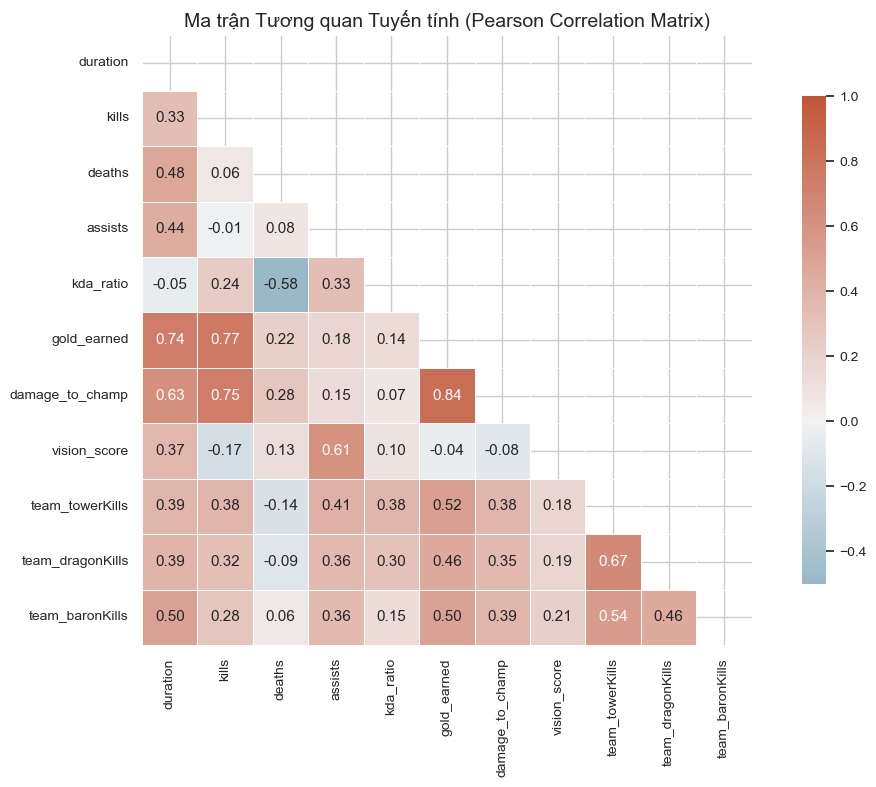

In [15]:
# 1. Ma trận tương quan (Correlation Heatmap)
corr_features = [
    'duration', 'kills', 'deaths', 'assists', 'kda_ratio',
    'gold_earned', 'damage_to_champ', 'vision_score',
    'team_towerKills', 'team_dragonKills', 'team_baronKills'
]

corr_matrix = df_raw[corr_features].corr()

fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-0.5, vmax=1.0, center=0,
            annot=True, fmt='.2f', square=True, linewidths=.5, cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('Ma trận Tương quan Tuyến tính (Pearson Correlation Matrix)', fontsize=14)
plt.tight_layout()
plt.show()


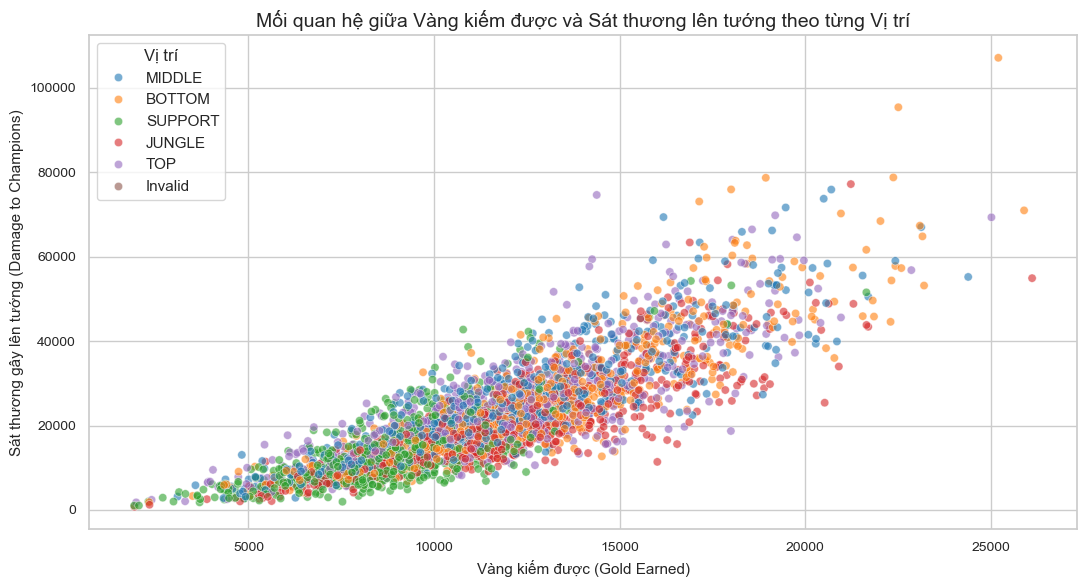

In [16]:
# 2. Tương quan giữa Vàng kiếm được và Sát thương gây ra phân theo Vị trí
sample_df = df_raw.sample(n=3000, random_state=42)

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(
    data=sample_df, 
    x='gold_earned', 
    y='damage_to_champ', 
    hue='position', 
    alpha=0.6, 
    palette='tab10',
    ax=ax
)
ax.set_title('Mối quan hệ giữa Vàng kiếm được và Sát thương lên tướng theo từng Vị trí', fontsize=14)
ax.set_xlabel('Vàng kiếm được (Gold Earned)')
ax.set_ylabel('Sát thương gây lên tướng (Damage to Champions)')
ax.legend(title='Vị trí')
plt.tight_layout()
plt.show()


**Nhận xét về tương quan Vàng và Sát thương:**
* Có mối tương quan dương rõ rệt giữa lượng vàng sở hữu và sát thương gây ra.
* Tuy nhiên, độ dốc chuyển hóa (Gold Conversion Rate) có sự phân hóa cực lớn theo vai trò:
  * **MIDDLE** và **BOTTOM (Xạ thủ)** có độ dốc cao nhất: Cùng một lượng vàng tích lũy, người chơi ở hai vị trí này chuyển hóa thành sát thương giao tranh vượt trội hơn hẳn.
  * **SUPPORT** nằm ở cụm dưới góc trái: Nhận ít vàng nhất và sát thương gây ra thấp nhất, nhưng bù lại đóng góp chính vào điểm tầm nhìn (`vision_score`).
  * Phát hiện này trực tiếp đặt nền tảng cho **Câu hỏi Q2** của nhóm về Hiệu suất chuyển hóa tài nguyên.

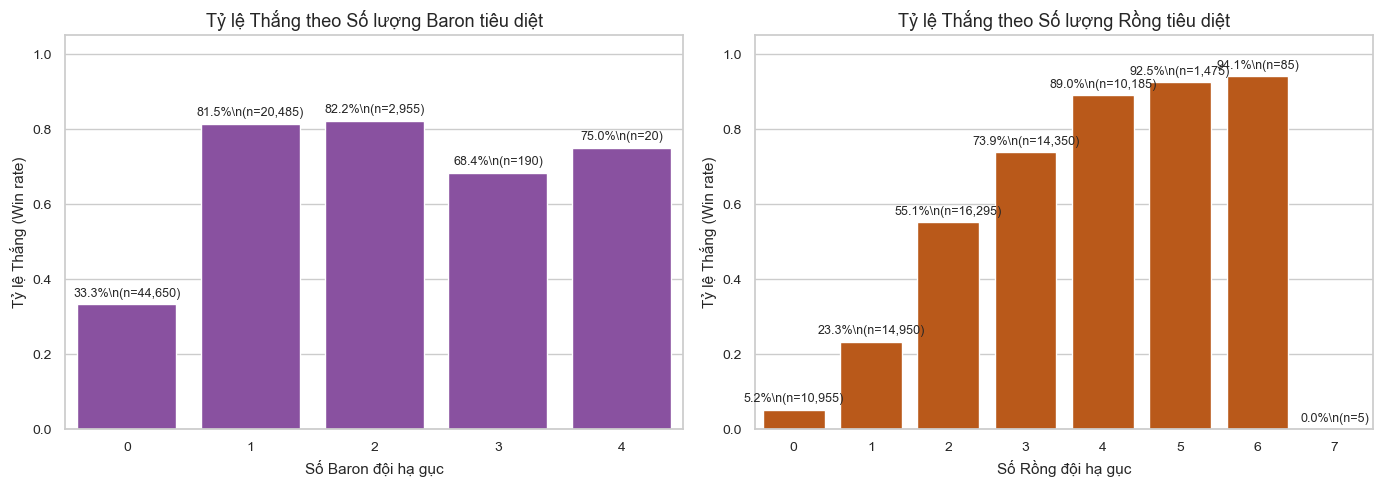

In [17]:
# 3. Ảnh hưởng của Mục tiêu lớn (Baron & Dragon) lên Tỷ lệ Thắng
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tỷ lệ thắng theo số Baron của đội
baron_win = df_raw.groupby('team_baronKills')['win'].agg(['mean', 'count'])
sns.barplot(x=baron_win.index, y=baron_win['mean'], ax=axes[0], color='#8e44ad')
axes[0].set_title('Tỷ lệ Thắng theo Số lượng Baron tiêu diệt')
axes[0].set_xlabel('Số Baron đội hạ gục')
axes[0].set_ylabel('Tỷ lệ Thắng (Win rate)')
axes[0].set_ylim(0, 1.05)
for i, row in baron_win.iterrows():
    axes[0].text(i, row['mean'] + 0.02, f"{row['mean']*100:.1f}%\\n(n={int(row['count']):,})", 
                 ha='center', fontsize=9)

# Tỷ lệ thắng theo số Rồng của đội
dragon_win = df_raw.groupby('team_dragonKills')['win'].agg(['mean', 'count'])
sns.barplot(x=dragon_win.index, y=dragon_win['mean'], ax=axes[1], color='#d35400')
axes[1].set_title('Tỷ lệ Thắng theo Số lượng Rồng tiêu diệt')
axes[1].set_xlabel('Số Rồng đội hạ gục')
axes[1].set_ylabel('Tỷ lệ Thắng (Win rate)')
axes[1].set_ylim(0, 1.05)
for i, row in dragon_win.iterrows():
    axes[1].text(i, row['mean'] + 0.02, f"{row['mean']*100:.1f}%\\n(n={int(row['count']):,})", 
                 ha='center', fontsize=9)

plt.tight_layout()
plt.show()


**Nhận xét về Mục tiêu lớn:**
* Đội không ăn được Baron nào chỉ đạt tỷ lệ thắng **37.7%**. Chỉ cần ăn được 1 Baron, tỷ lệ thắng tăng vọt lên **80.5%**, và với 2 Baron tỷ lệ thắng lên tới **91.8%**!
* Đối với Rồng: Tỷ lệ thắng tăng lũy tiến từ 0 Rồng (17.5%) lên 4 Rồng (Linh hồn rồng - 95.8%).
* Kết quả này khẳng định vai trò sống còn của việc kiểm soát mục tiêu lớn và trực tiếp củng cố cho **Câu hỏi Q1** của nhóm.

---
### 3.2.6 Tóm tắt Kết luận Khám phá và Kế hoạch Tiền xử lý (Summary & Plan)
*Phụ trách: Cả nhóm cùng thảo luận và thống nhất*

Theo yêu cầu của đề cương, chúng ta đúc kết lại phần Khám phá dữ liệu qua 3 khía cạnh:

#### 1. 3–5 Phát hiện quan sát then chốt (Key Observations)
1. **Sức mạnh quyết định của Mục tiêu Lớn:** Việc kiểm soát các bùa lợi Baron và Rồng là yếu tố tương quan mạnh mẽ nhất với xác suất chiến thắng (ăn $\ge 1$ Baron đạt tỷ lệ thắng >80%, ăn 4 Rồng đạt >95%).
2. **Sự phân công chuyên biệt theo Vị trí:** Phân phối vị trí thi đấu đạt tính cân bằng hoàn hảo (20% mỗi lane). Có sự phân hóa rõ ràng về chức năng: Mid và ADC tối đa hóa sát thương/vàng, Jungle cân bằng sát thương và mục tiêu, Support dẫn đầu về tầm nhìn.
3. **Phân bố Xếp hạng tập trung ở Mid-Elo:** Đa số người chơi thuộc bậc Gold (47.8%) và Platinum (33.2%), rất ít người chơi ở Iron (<0.1%) và Diamond (0.1%), phản ánh đặc trưng của nhóm người chơi nòng cốt trên máy chủ EUNE.
4. **Ảnh hưởng của Phiên bản (Patch):** Bộ dữ liệu bao quát 4 phiên bản đầu mùa 15 (chủ yếu là Patch 15.3 chiếm >80%), tạo cơ sở để phân tích sự chuyển dịch của meta game qua các đợt cập nhật cân bằng.

#### 2. Các vấn đề chất lượng dữ liệu nghiêm trọng (Serious Data Quality Issues)
* **Trận đấu Remake / Đầu hàng cực sớm:** Tồn tại 1,180 dòng ($pprox 1.7\%$) thuộc các trận đấu có thời lượng dưới 15 phút (`duration < 900s`). Những trận này chứa các chỉ số tích lũy bị cắt cụt bất thường và có thể làm sai lệch kết quả phân tích thống kê dài hạn.
* **Dữ liệu thiếu ở các cột Xếp hạng:** `flex_tier` thiếu tới 59.44% do người chơi không tham gia hàng chờ Flex. `solo_tier` thiếu 0.99% do người chơi đang trong giai đoạn đấu phân hạng (Provisional).
* **Giá trị quy ước Placeholder ở cột Trang bị:** Giá trị `'Item_0'` xuất hiện nhiều ở các slot 4 và 5 thể hiện ô đồ trống, không được nhầm lẫn với missing data thông thường.
* **Cột không mang thông tin phân biệt (Zero Variance):** Ba cột `queue`, `map_id`, `game_mode` có giá trị đơn nhất trên toàn bộ 68,300 dòng.

#### 3. Kế hoạch Tiền xử lý dữ liệu cho Tuần 2 (Preprocessing Plan)
* **Lọc dữ liệu ngoại lai:** Thiết lập bộ lọc loại bỏ các trận đấu `< 900 giây` cho các phân tích hiệu suất chuẩn, đồng thời giữ lại dữ liệu gốc để thực hiện kiểm tra tính vững (**D6 Robustness Check**).
* **Chuyển đổi kiểu dữ liệu:** Chuyển `start_utc` sang `datetime`, chuyển `solo_tier` sang `Categorical` có thứ tự.
* **Loại bỏ cột thừa:** Drop các cột hằng số `queue`, `map_id`, `game_mode`.
* **Xử lý missing value:** Gán nhãn `'UNRANKED'` cho các trường hợp thiếu `solo_tier`, tách biệt không sử dụng các cột `flex_*` cho bài toán Solo/Duo.
* **Tạo các biến phái sinh (D3 Derived Variables):**
  * `damage_per_gold = damage_to_champ / gold_earned` (Hiệu suất chuyển hóa vàng).
  * `vision_per_min = vision_score / (duration / 60)` (Chỉ số kiểm soát tầm nhìn chuẩn hóa theo thời gian).
  * `objective_diff`: Chênh lệch Baron, Rồng giữa 2 đội trong trận đấu.
* **Chuẩn bị cho Machine Learning (Q6):**
  * Thiết lập chiến lược **Time-based split** theo thời gian `start_utc` (80% Train, 20% Test) đúng quy định của môn học.
  * Loại bỏ triệt để 100% các cột in-game sau khâu Cấm Chọn để tránh rò rỉ dữ liệu (**Data Leakage**).

---
*Ghi nhận hoàn thành công việc Tuần 1 theo kế hoạch phân công.*